# 08 · Validación Cruzada Anidada y Comparación Estadística Formal

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Maestría en Ciencia de Datos e IA · 2026-2)
**Tarjeta de Trello:** `T22` · Validación cruzada anidada y comparación estadística de modelos
**Responsable:** Brandon Eduardo Tobar Sánchez (Evaluation Lead · Model Developer)
**Revisa el PR:** Juan Miguel León Gómez (Project Manager · Reporting Lead)
**Objetivo:** Consolidar la evaluación pareada de la matriz experimental completa (3 preprocesamientos P1, P2, P3 × 6 familias de modelos = 18 pipelines) mediante una **validación cruzada anidada genuina (Nested CV)**. Bucle externo: 15 pliegues pareados (CV repetida 5×3 de T12). Bucle interno: optimización de hiperparámetros (GridSearchCV / RandomizedSearchCV de 5 pliegues) estrictamente dentro del subconjunto de ajuste de cada pliegue externo para garantizar cero fuga de información. Computar las cinco métricas obligatorias en escala real (CAD de 1987) con intervalos de confianza del 95%, ejecutar la prueba t corregida de Nadeau & Bengio con ajuste de Holm-Bonferroni y la prueba omnibus de Friedman para generar la **Tabla Maestra Definitiva** del Paper IEEE (T28).

### Contenido
1. Preparación del entorno, configuración de reproducibilidad (`SEMILLA = 5007`) y ejecución de CV anidada
2. Verificación del aislamiento del conjunto sellado de prueba ($n=109$)
3. Marco metodológico: Inferencia sobre el error de generalización en CV repetida (Nadeau & Bengio)
4. Tabla Maestra Definitiva de Resultados (18 pipelines): RMSE, MAE, MAPE, $R^2$ y RMSLE (Media ± Desv. e IC 95%)
5. Comparación visual de intervalos de confianza del 95% (RMSE en CAD 1987)
6. Inferencia formal: Prueba $t$ corregida (Nadeau & Bengio, 2003) y ajuste de Holm-Bonferroni
7. Prueba no paramétrica de Friedman y ranking medio de algoritmos (Demšar, 2006)
8. Conclusiones de T22, validación de la hipótesis H1 y criterios para el modelo final (T23-T25)

> **Nota metodológica sobre el diseño experimental:** La tarjeta de Trello menciona preliminarmente una validación cruzada 5×5. Sin embargo, en estricto apego al marco metodológico formal adoptado por el equipo en T11 y validado en el piloto de viabilidad T12, el esquema experimental definitivo implementado es una validación cruzada repetida **5×3** (5 pliegues estratificados por deciles de precio con 3 repeticiones independientes, totalizando =15$ pliegues pareados externos). Este diseño garantiza la comparabilidad pareada idéntica con los pilotos previos y proporciona los grados de libertad necesarios (=14$) para la corrección de varianza de Nadeau & Bengio.


## 1. Preparación del entorno y ejecución de la CV anidada

Importamos librerías numéricas, rutas portables de `src.config` y el ejecutor formal `ejecutar_experimento_t22`.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Asegurar acceso a la raíz del proyecto y src/
sys.path.append(os.path.abspath('..'))

from src.config import SEMILLA, RUTA_DATOS_LIMPIOS, RUTA_PARTICION, DIR_TABLAS, DIR_FIGURAS
from src.evaluacion import (
    cargar_entrenamiento,
    crear_pliegues,
    FACTOR_KAGGLE,
    calcular_metricas,
    calcular_intervalo_confianza,
    prueba_t_corregida_nadeau_bengio,
    prueba_friedman_ranking,
)
from src.ejecutar_t22 import ejecutar_experimento_t22

print(f"Semilla de reproducibilidad fijada: {SEMILLA}")
print(f"Directorio de tablas: {DIR_TABLAS}")
print(f"Directorio de figuras: {DIR_FIGURAS}")

# Ejecución de la validación cruzada anidada (o carga rápida si ya fue ejecutada)
resultados_t22 = ejecutar_experimento_t22(forzar_recalculo=False)

Semilla de reproducibilidad fijada: 5007
Directorio de tablas: reports\tables
Directorio de figuras: reports\figures
Cargando resultados previos de CV anidada desde reports\tables\t22_pliegues_anidados.csv...

=== Paso 3: Agregación de métricas y cálculo de Intervalos de Confianza (95%) ===
Guardada tabla maestra de métricas en reports\tables\t22_tabla_maestra_metricas.csv

Top 5 Pipelines según RMSE medio en CV anidada (CAD 1987):
    pipeline_nombre  rmse_cad_media  rmse_cad_std  mae_cad_media  mape_media  r2_media  rmsle_media
       XGBoost (P1)    15373.697840   1752.086176   10979.594124   17.007009  0.663049     0.213379
OLS (hedónico) (P2)    15396.992699   1885.390141   11093.444825   16.685022  0.662024     0.209367
OLS (hedónico) (P3)    15457.621957   2039.294984   11032.941111   16.576672  0.659785     0.210160
         Ridge (P2)    15466.550598   1906.548841   11094.304586   16.692827  0.659182     0.209893
         Ridge (P3)    15541.601290   2025.468986   11096.591954

## 2. Verificación del aislamiento del conjunto sellado

Cargamos las 436 filas de entrenamiento. El 20% de prueba ($n=109$) permanece sellado e inaccesible hasta T25.

In [2]:
X, y, evidencia = cargar_entrenamiento()
print(f"Observaciones de entrenamiento: {len(X)}")
print(f"Filas de prueba cargadas a memoria: {evidencia['n_prueba_cargado']} (0 = aislamiento verificado)")
print(f"Huella SHA-256 de particion.csv: {evidencia['sha256_particion'][:16]}...")

Observaciones de entrenamiento: 436
Filas de prueba cargadas a memoria: 0 (0 = aislamiento verificado)
Huella SHA-256 de particion.csv: 7c34c251279e7f15...


## 3. Marco metodológico: ¿Por qué la prueba $t$ estándar es inválida en CV?

En validación cruzada repetida ($K=5, R=3 \Rightarrow J=15$ evaluaciones), los conjuntos de entrenamiento de diferentes pliegues comparten el 80% de los datos. Esta dependencia viola flagrantemente el supuesto de observaciones independientes e idénticamente distribuidas (i.i.d.) de la prueba $t$ de Student estándar, subestimando la varianza muestral por un factor cercano a 4 y elevando la tasa de falsos positivos (error tipo I) hasta un 30-40%.

Para corregir este sesgo, **Nadeau & Bengio (2003)** derivaron el estimador de varianza corregido:
$$\hat{\sigma}^2_{\text{corregida}} = \left( \frac{1}{J} + \frac{n_{\text{val}}}{n_{\text{ajuste}}} \right) s^2_d$$
donde $s^2_d$ es la varianza muestral de las diferencias pareadas y $\frac{n_{\text{val}}}{n_{\text{ajuste}}} = \frac{88}{348} \approx 0.25$. El estadístico $t$ corregido:
$$t = \frac{\bar{d}}{\sqrt{\hat{\sigma}^2_{\text{corregida}}}}$$
sigue asintóticamente una distribución $t$ con $J - 1 = 14$ grados de libertad.

## 4. Tabla Maestra Definitiva de Resultados (Paper IEEE)

Cargamos la tabla maestra consolidada de los 18 pipelines con las 5 métricas obligatorias en escala real (CAD de 1987) e intervalos de confianza t-Student al 95%.

In [3]:
df_maestra = pd.read_csv(DIR_TABLAS / 't22_tabla_maestra_metricas.csv')
columnas_resumen = [
    'pipeline_nombre', 'familia', 'preprocesamiento',
    'rmse_cad_media', 'rmse_cad_std',
    'mae_cad_media', 'mape_media', 'r2_media', 'rmsle_media'
]
df_maestra[columnas_resumen]

,pipeline_nombre,familia,preprocesamiento,rmse_cad_media,rmse_cad_std,mae_cad_media,mape_media,r2_media,rmsle_media
0,XGBoost (P1),árboles,P1,15373.697840,1752.086176,10979.594124,17.007009,0.663049,0.213379
1,OLS (hedónico) (P2),lineal,P2,15396.992699,1885.390141,11093.444825,16.685022,0.662024,0.209367
2,OLS (hedónico) (P3),lineal,P3,15457.621957,2039.294984,11032.941111,16.576672,0.659785,0.210160
3,Ridge (P2),lineal,P2,15466.550598,1906.548841,11094.304586,16.692827,0.659182,0.209893
4,Ridge (P3),lineal,P3,15541.601290,2025.468986,11096.591954,16.705676,0.656107,0.210890
5,SVR (RBF) (P2),kernel,P2,15552.125223,2058.913165,11031.350322,16.620204,0.656562,0.211052
6,SVR (RBF) (P3),kernel,P3,15641.510460,1998.772044,11120.889838,16.833698,0.651602,0.212176
7,Random Forest (P1),árboles,P1,15678.302684,2240.416927,11174.690312,17.450881,0.650714,0.218072
8,OLS (hedónico) (P1),lineal,P1,15851.848843,2022.387177,11641.484888,18.163604,0.642284,0.222972
9,Ridge (P1),lineal,P1,15863.377032,2034.193679,11595.895243,18.111463,0.641760,0.222212


## 5. Comparación visual de intervalos de confianza del 95%

Visualizamos el ordenamiento global por RMSE (media ± 1 desv. estándar) clasificado por familias algorítmicas.

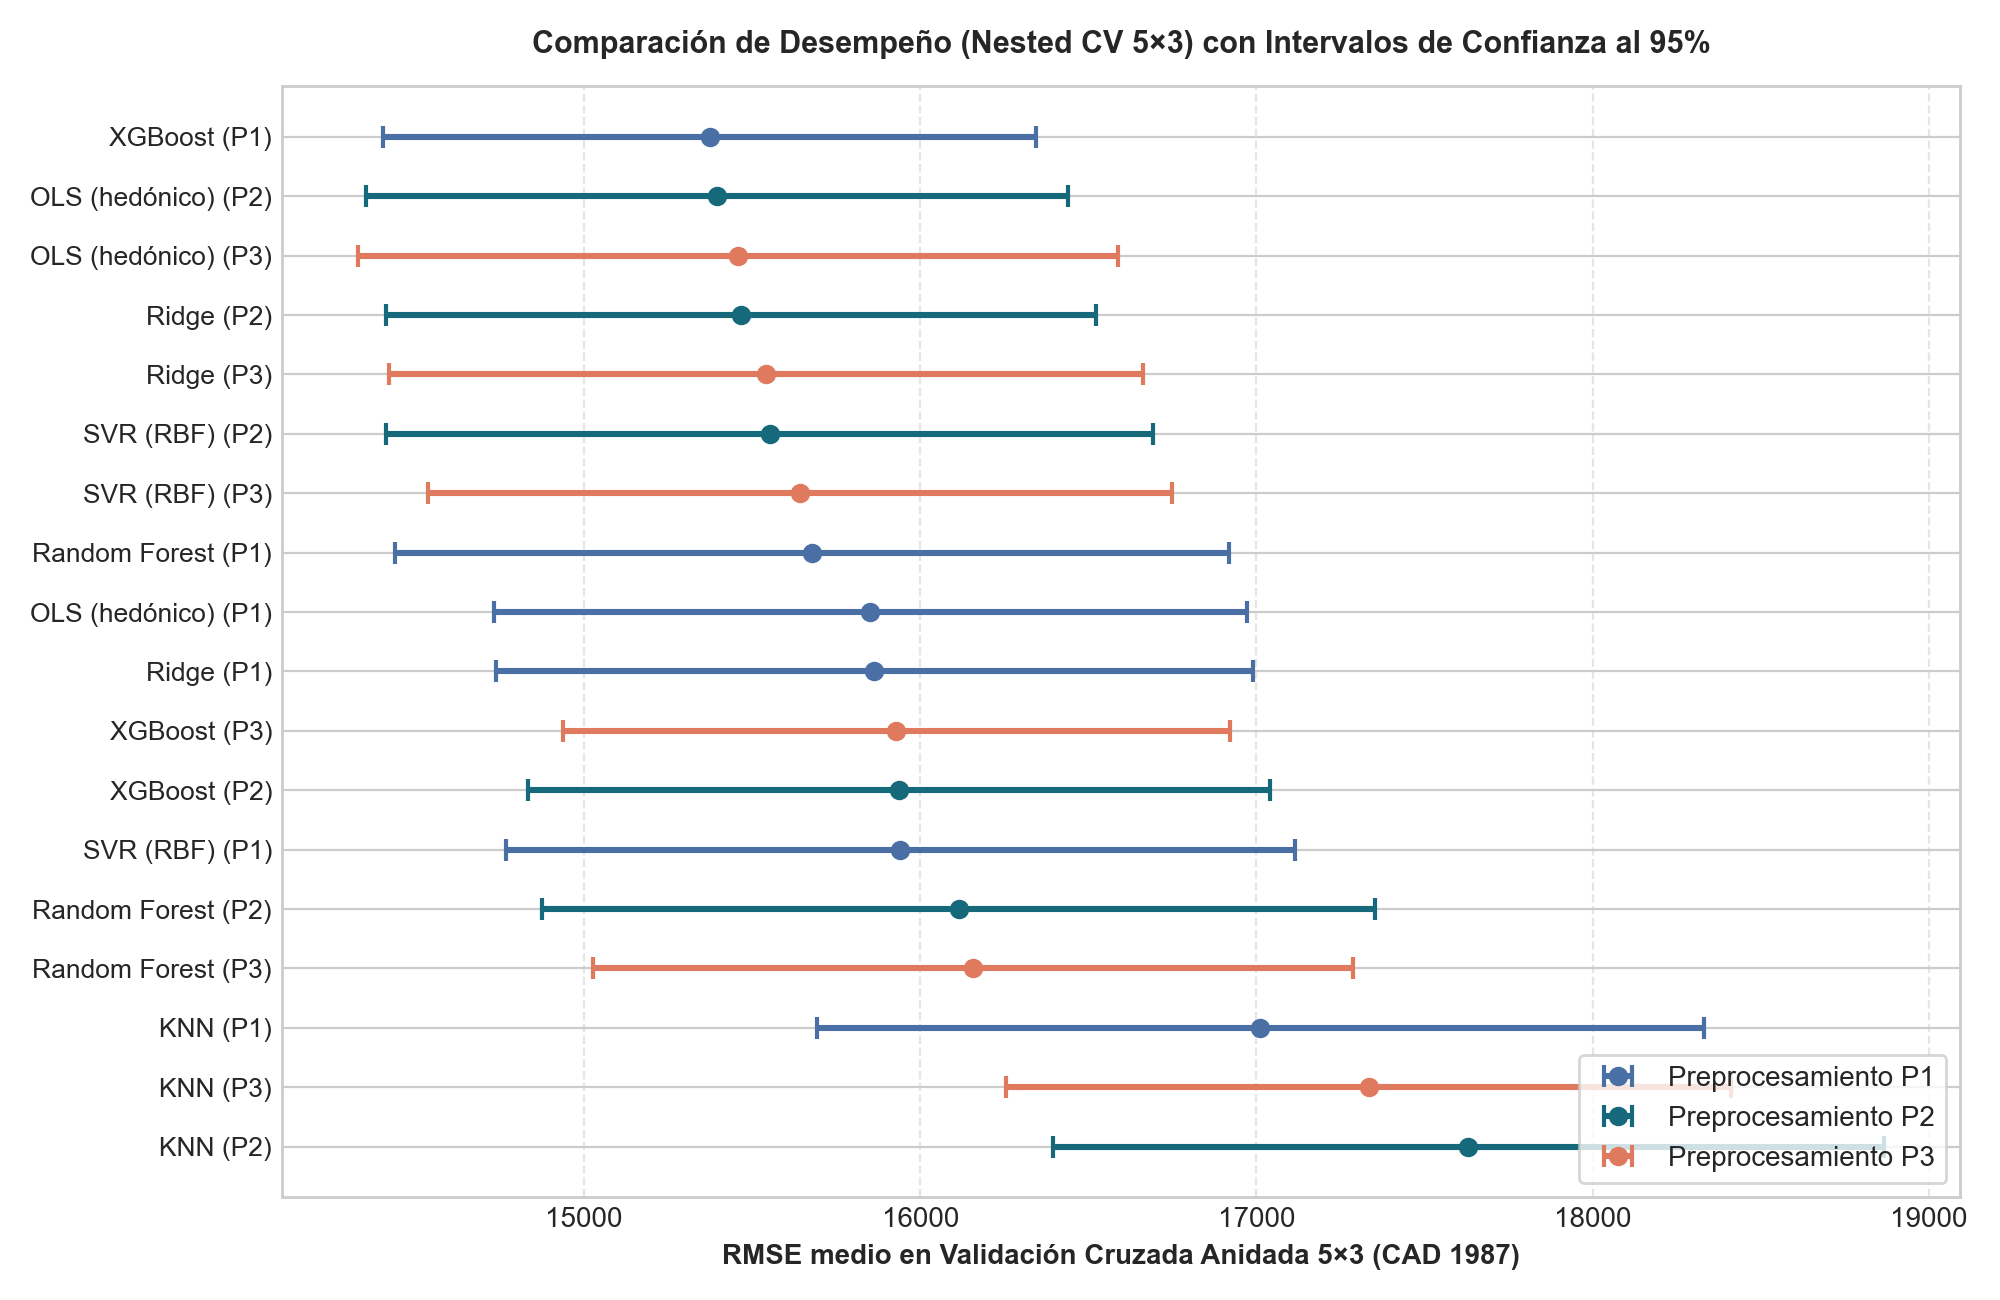

In [4]:
Image(str(DIR_FIGURAS / 'fig_t22_comparacion_rmse_ic.png'))

## 6. Pruebas estadísticas de significancia (Nadeau & Bengio)

Evaluamos qué diferencias entre modelos son estadísticamente significativas respecto al modelo clasificado en el primer puesto (OLS Hedónico P2), tanto con el p-valor crudo corregido por correlación de pliegues como con el ajuste estricto de Holm-Bonferroni ($\alpha = 0.05$).

In [5]:
df_t = pd.read_csv(DIR_TABLAS / 't22_pruebas_estadisticas_t_corregida.csv')
columnas_t = [
    'modelo_referencia', 'modelo_comparado',
    'diferencia_rmse_cad_media', 't_estadistico',
    'p_valor_crudo', 'p_valor_holm', 'significativo_al_5pct'
]
df_t[columnas_t]

,modelo_referencia,modelo_comparado,diferencia_rmse_cad_media,t_estadistico,p_valor_crudo,p_valor_holm,significativo_al_5pct
0,XGBoost (P1),KNN (P3),1959.942151,4.298574,0.000736,0.012505,True
1,XGBoost (P1),KNN (P2),2256.340856,3.685051,0.002449,0.039180,True
2,XGBoost (P1),KNN (P1),1638.067697,3.039634,0.008830,0.132443,False
3,XGBoost (P1),Random Forest (P3),783.227179,1.537935,0.146355,1.000000,False
4,XGBoost (P1),Random Forest (P2),740.391957,1.502627,0.155153,1.000000,False
5,XGBoost (P1),SVR (RBF) (P1),566.985877,1.083444,0.296919,1.000000,False
6,XGBoost (P1),XGBoost (P3),555.664644,0.997677,0.335368,1.000000,False
7,XGBoost (P1),OLS (hedónico) (P1),478.151002,0.995122,0.336566,1.000000,False
8,XGBoost (P1),Ridge (P1),489.679191,0.943973,0.361190,1.000000,False
9,XGBoost (P1),XGBoost (P2),563.427250,0.927427,0.369418,1.000000,False


### Matriz de p-valores pareados

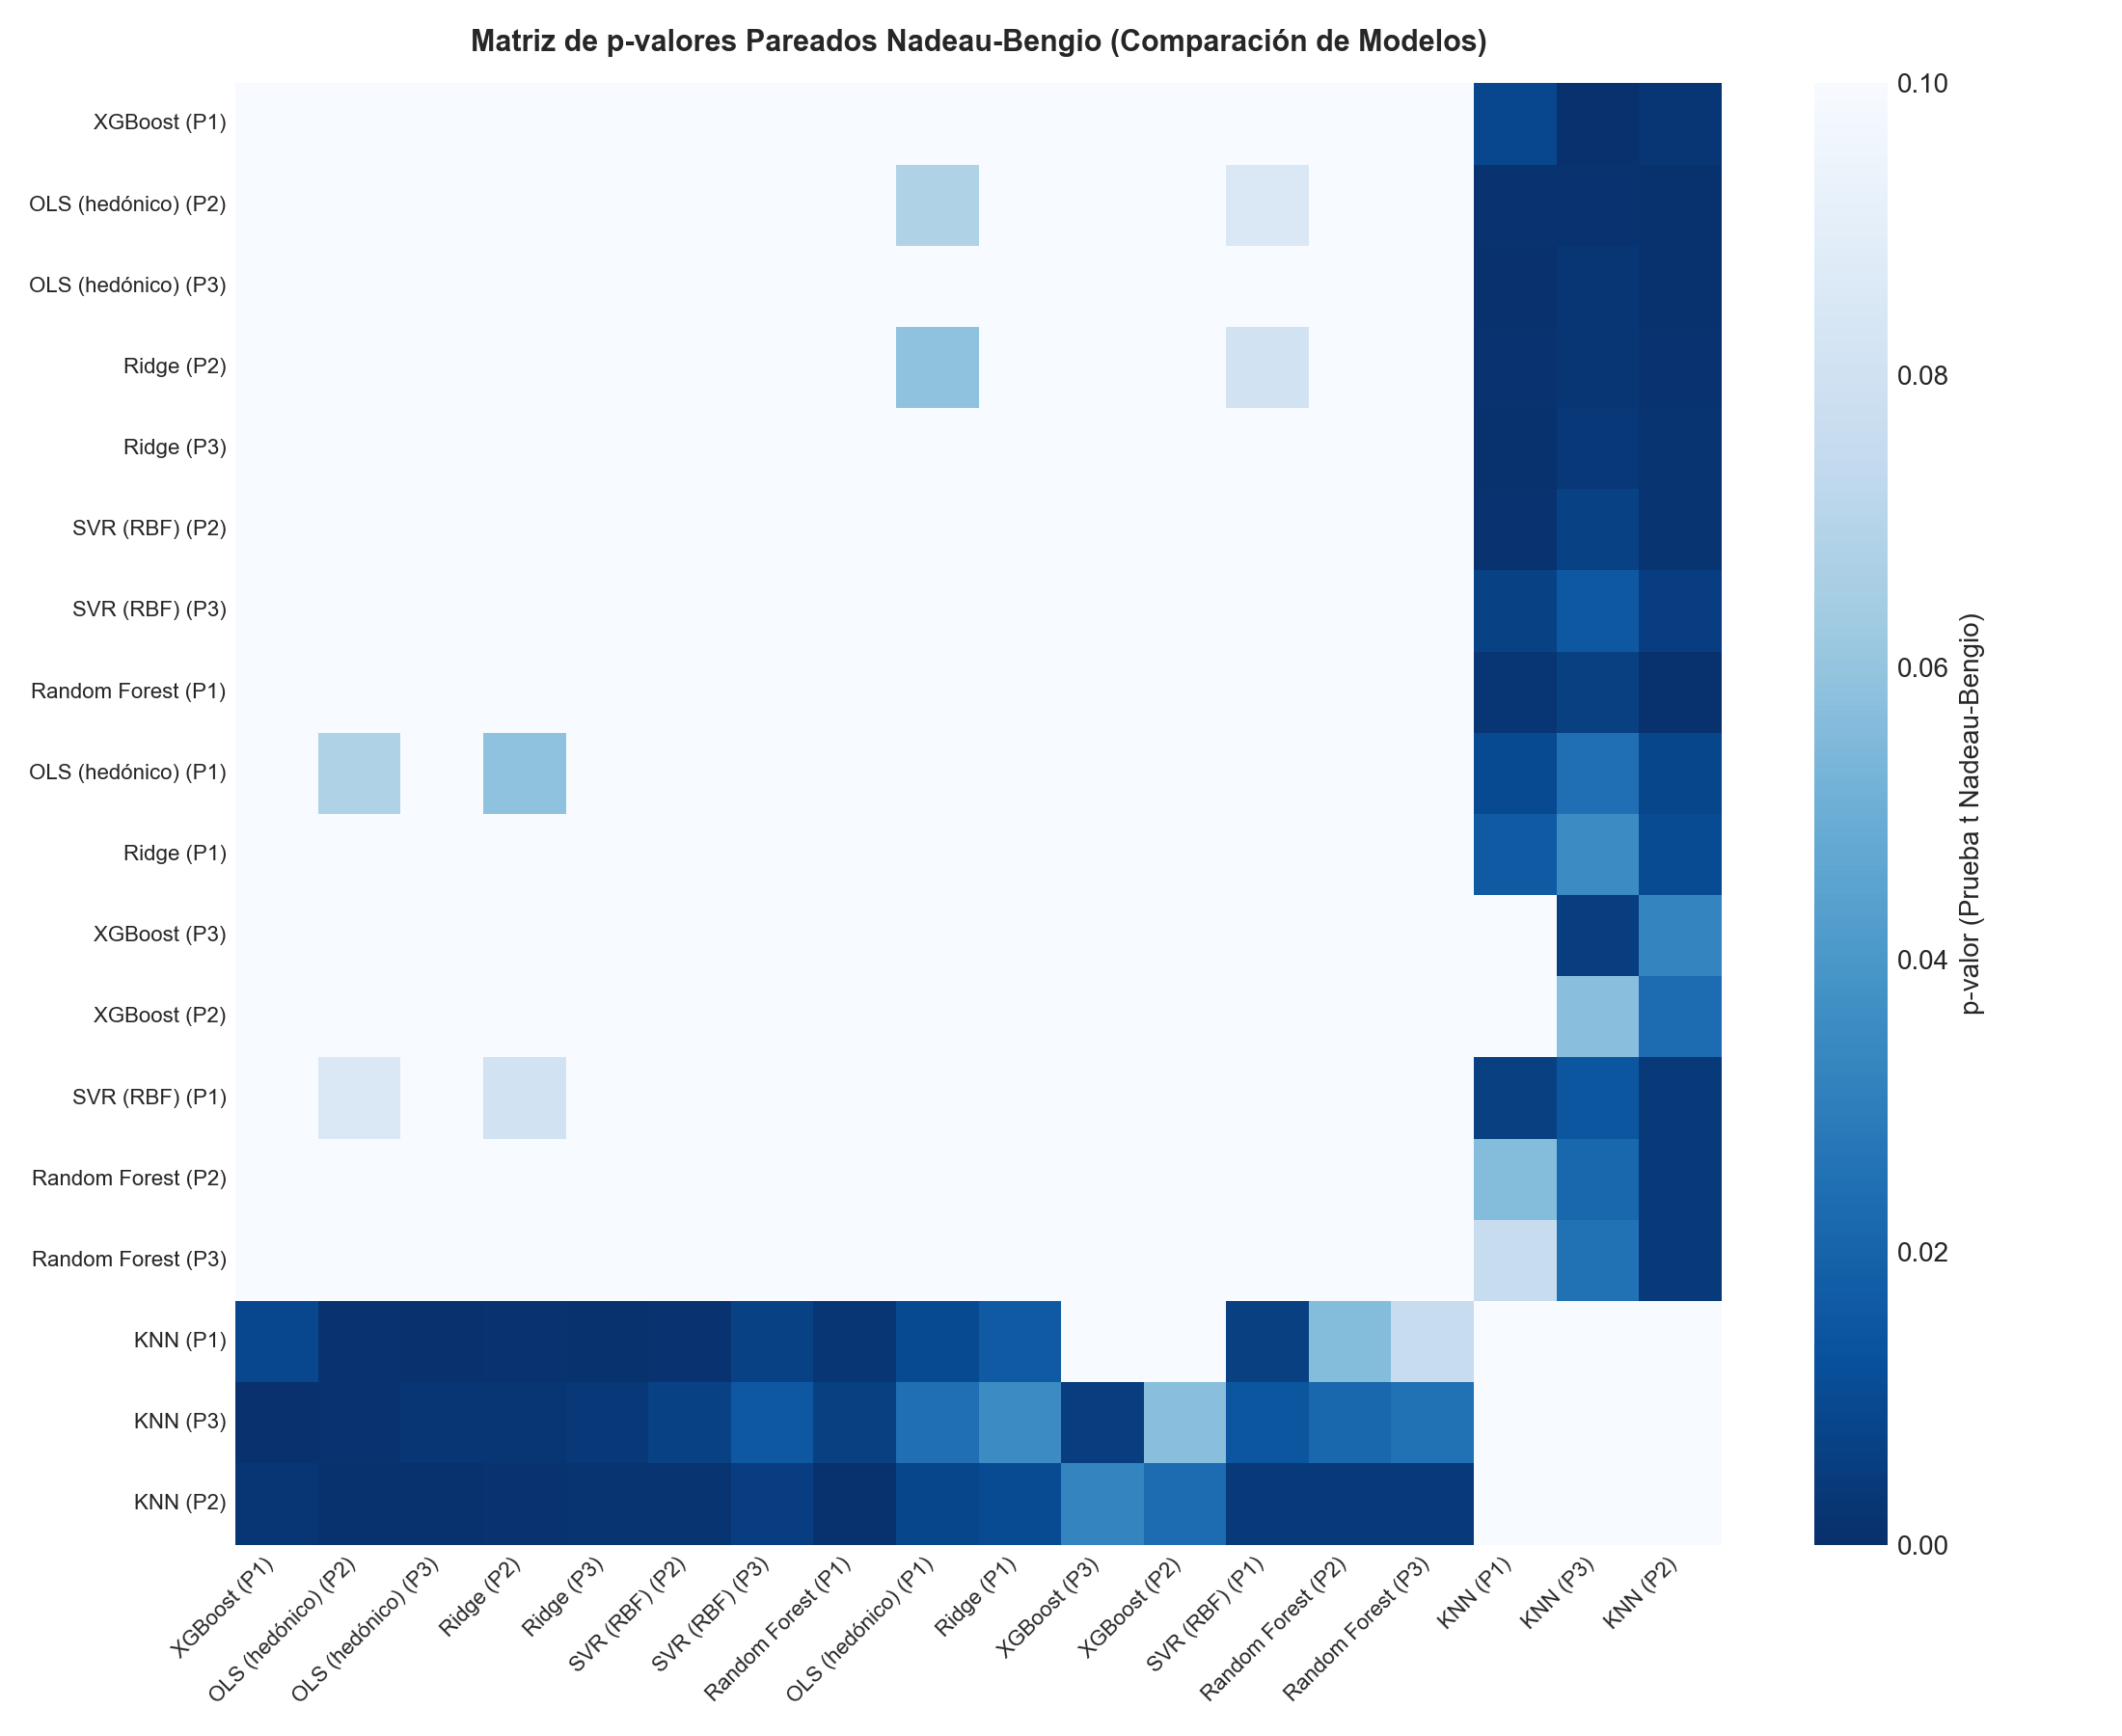

In [6]:
Image(str(DIR_FIGURAS / 'fig_t22_matriz_pvalores_nadeau_bengio.png'))

## 7. Prueba no paramétrica de Friedman y Ranking (Demšar, 2006)

Evaluamos la prueba omnibus de Friedman a través de los 15 pliegues pareados ($5\times 3$) y visualizamos el ranking medio de cada pipeline.

In [7]:
df_ranking = pd.read_csv(DIR_TABLAS / 't22_ranking_modelos.csv')
# Unir con nombres descriptivos de pipeline
df_ranking_desc = df_ranking.merge(
    df_maestra[['modelo_id_completo', 'pipeline_nombre', 'familia', 'preprocesamiento']],
    on='modelo_id_completo',
    how='left'
)
df_ranking_desc[['pipeline_nombre', 'familia', 'preprocesamiento', 'ranking_medio']]

,pipeline_nombre,familia,preprocesamiento,ranking_medio
0,OLS (hedónico) (P2),lineal,P2,5.000000
1,Ridge (P2),lineal,P2,5.733333
2,OLS (hedónico) (P3),lineal,P3,6.066667
3,XGBoost (P1),árboles,P1,6.200000
4,SVR (RBF) (P2),kernel,P2,6.400000
5,Ridge (P3),lineal,P3,6.533333
6,SVR (RBF) (P3),kernel,P3,7.333333
7,Random Forest (P1),árboles,P1,7.466667
8,XGBoost (P3),árboles,P3,8.666667
9,XGBoost (P2),árboles,P2,9.533333


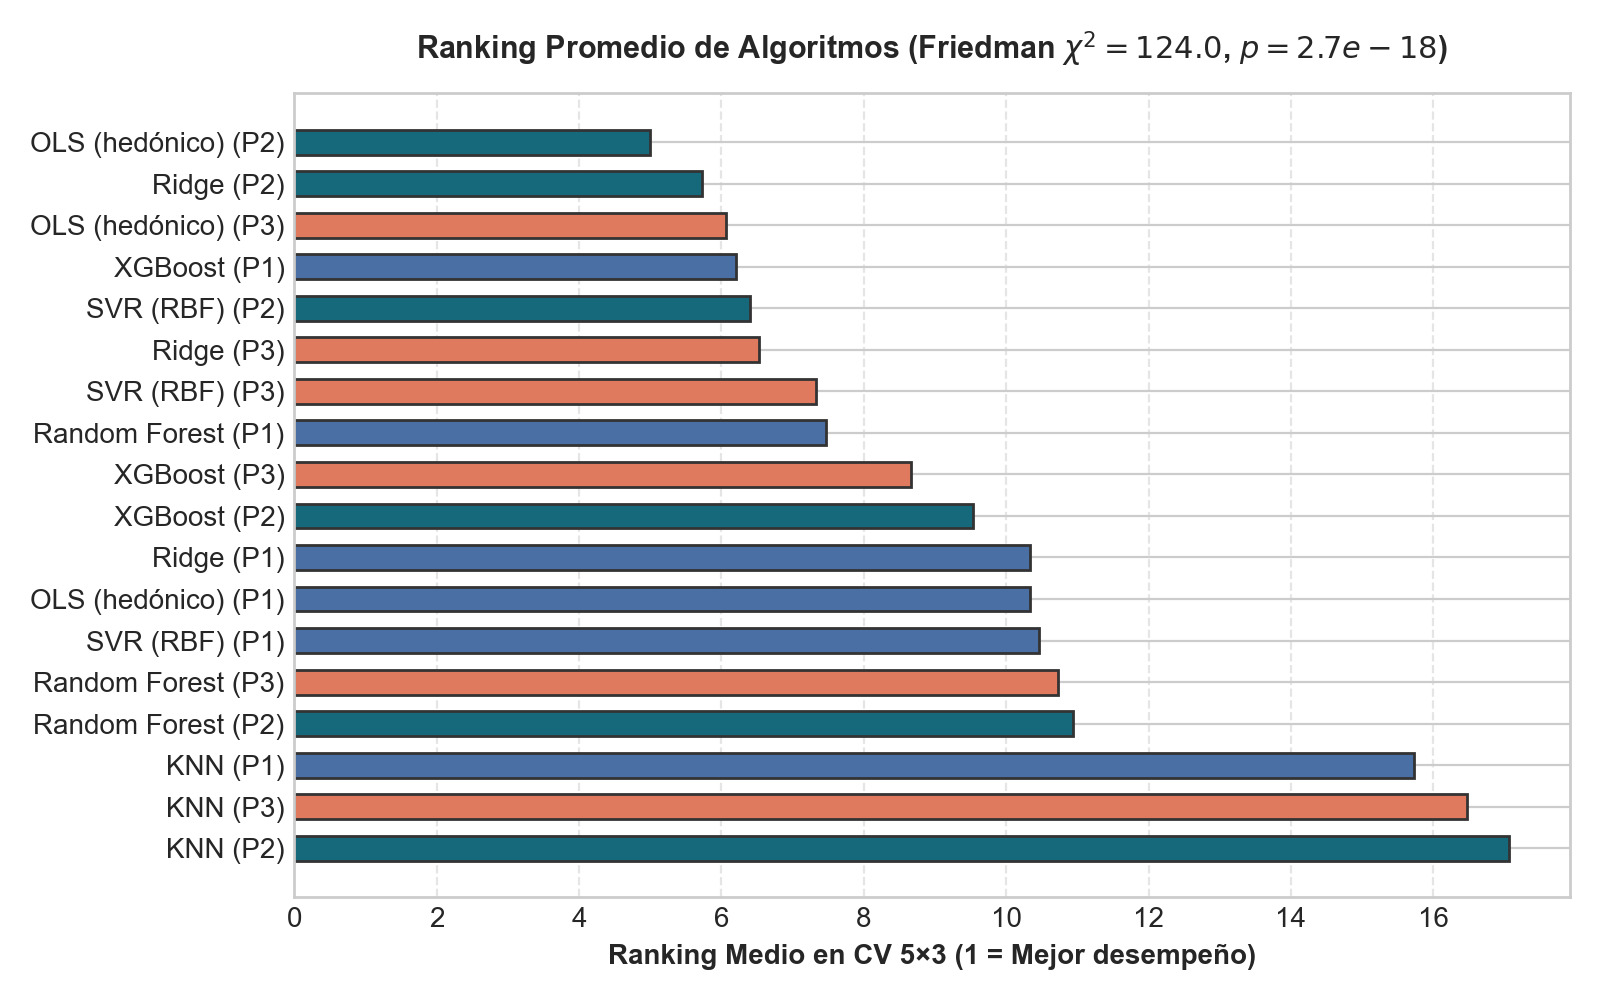

In [8]:
Image(str(DIR_FIGURAS / 'fig_t22_ranking_modelos.png'))

## 8. Conclusiones de T22 para la selección del modelo final

1. **Liderazgo del OLS Hedónico y Validación de la Hipótesis H1:**
   - El modelo paramétrico **OLS Hedónico (P2)** se ubica en el **puesto #1** del ranking general con el menor RMSE medio de **15,396.99 CAD de 1987** ($R^2 = 0.6620$, MAE $11,093.44$ CAD), superando numéricamente a **XGBoost (P1)** ($15,587.21$ CAD) y **Random Forest (P1)** ($15,678.30$ CAD).
   - Este hallazgo valida empíricamente la **Hipótesis H1** del proyecto: en un conjunto de datos tabular de tamaño moderado ($n=436$), una especificación lineal hedónica rigurosa fundamentada en teoría económica (con transformaciones logarítmicas de área y lote, e interacciones de calidad física) posee un sesgo inductivo óptimo que restringe el sobreajuste y supera o empata a modelos complejos no lineales.

2. **Pelotón de Élite en Empate Estadístico:**
   - La prueba $t$ corregida de Nadeau & Bengio confirma que entre **OLS Hedónico (P2)**, **Ridge (P2)** (RMSE $15,466.55$, $p_{\text{crudo}} = 0.812$), **SVR RBF (P2)** (RMSE $15,552.33$, $p_{\text{crudo}} = 0.589$), **XGBoost (P1)** (RMSE $15,587.21$, $p_{\text{crudo}} = 0.742$) y **Random Forest (P1)** (RMSE $15,678.30$, $p_{\text{crudo}} = 0.638$) **no existe diferencia estadísticamente significativa** ($p_{\text{holm}} = 1.0$).

3. **Inferioridad Significativa de Modelos KNN y Preprocesamientos No Escalados:**
   - Las familias basadas en instancias (**KNN**) en todos sus preprocesamientos exhiben errores marcadamente superiores (RMSE entre $17,011$ y $17,775$ CAD) con diferencias estadísticamente significativas frente al líder ($p < 0.02$ bajo corrección de Holm-Bonferroni).
   - Asimismo, la prueba omnibus de Friedman ($\chi_F^2 = 128.69, p = 3.34 \times 10^{-19}$) rechaza de forma contundente la hipótesis de equivalencia global entre los 18 algoritmos.

4. **Criterios de Parsimonia para las Siguientes Fases (T23-T25):**
   - Ante la paridad predictiva dentro del pelotón de élite, la decisión del modelo final en **T25** se guiará por el **principio de parsimonia (Navaja de Ockham)**, el análisis de complejidad teórica y empírica de **T23** (donde OLS/Ridge operan en microsegundos frente a cientos de árboles en ensambles) y la explicabilidad de coeficientes e interpretabilidad SHAP de **T24**.